# 🔥 WILDFIRE DETECTION — DEEP LEARNING LAB
### ResNet50 · PyTorch · Jupyter Notebook · Training Analytics

Notebook này là giao diện học tập để đọc code theo từng bước, kiểm tra dữ liệu, chạy huấn luyện và phân tích kết quả.

> **Cảnh báo dữ liệu:** Dataset đi kèm là ảnh mô phỏng được tạo bằng đồ họa, chỉ dùng kiểm tra pipeline. Accuracy trên dataset này không đại diện cho khả năng phát hiện cháy rừng ngoài thực tế. Không dùng cho cảnh báo hoặc quyết định an toàn.

**Các phần trong notebook**
1. Kiểm tra môi trường và GPU.
2. Kiểm tra cấu trúc dataset.
3. Khám phá và hiển thị ảnh.
4. Giải thích kiến trúc ResNet50.
5. Chạy training có progress bar và log từng batch.
6. Đọc biểu đồ Accuracy/Loss.
7. Phân tích Confusion Matrix và classification report.
8. Thử dự đoán một ảnh và lưu kết quả.


## 0A. Cài thư viện tự động cho Kernel đang chọn

Chạy cell này một lần sau khi mở notebook. Nó cài các package từ `requirements.txt` vào **đúng Python interpreter đang chạy notebook**. PyTorch/TorchVision có dung lượng lớn nên cần Internet và có thể mất vài phút. Nếu cài xong mà import vẫn báo lỗi, chọn Restart Kernel rồi chạy lại từ đầu.

Khuyến nghị: dùng kernel `Python 3.11 - Wildfire Detection` sau khi chạy `setup_windows.bat`.

In [1]:
from pathlib import Path
import sys, subprocess

PROJECT_ROOT = Path.cwd()
requirements_file = PROJECT_ROOT / 'requirements.txt'
if not requirements_file.exists():
    # Cho phép chạy notebook khi VS Code mở trực tiếp thư mục notebooks
    PROJECT_ROOT = Path.cwd().parent
    requirements_file = PROJECT_ROOT / 'requirements.txt'

if not requirements_file.exists():
    raise FileNotFoundError('Không tìm thấy requirements.txt. Hãy mở thư mục gốc của dự án trong VS Code.')

print('Notebook Python:', sys.executable)
print('Installing packages from:', requirements_file)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--upgrade', 'pip'])
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(requirements_file)])
print('Cài package hoàn tất. Nếu cell import kế tiếp chưa nhận package, hãy Restart Kernel.')


Notebook Python: c:\Users\MSI\AppData\Local\Programs\Python\Python311\python.exe
Installing packages from: d:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\requirements.txt
Cài package hoàn tất. Nếu cell import kế tiếp chưa nhận package, hãy Restart Kernel.


## 0. Chuẩn bị thư mục

Mở notebook từ thư mục gốc `Wildfire-Detection-Training-Analysis` để các đường dẫn tương đối hoạt động chính xác.

In [2]:
from pathlib import Path
import sys, os, json, platform, subprocess
ROOT = Path.cwd()
DATA_DIR = ROOT / "Wildfire-smoke"
OUTPUT_DIR = ROOT / "checkpoints"

print("Project:", ROOT)
print("Python:", sys.version)
print("Platform:", platform.platform())
print("Dataset exists:", DATA_DIR.exists())
print("Output folder:", OUTPUT_DIR)


Project: d:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\notebooks
Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
Platform: Windows-10-10.0.26200-SP0
Dataset exists: False
Output folder: d:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\notebooks\checkpoints


## 1. Kiểm tra thư viện, PyTorch và GPU

In [3]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Đang chạy CPU. Training ResNet50 có thể chậm.")


PyTorch: 2.15.0+cpu
TorchVision: 0.29.2+cpu
CUDA available: False
Đang chạy CPU. Training ResNet50 có thể chậm.


c:\Users\MSI\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Kiểm tra dataset và số lượng ảnh

`ImageFolder` đọc tên thư mục con làm nhãn. Tên class được sắp xếp theo alphabet nên cần xem `class_to_idx` trước khi diễn giải kết quả.

In [4]:

from pathlib import Path
from torchvision import datasets

# Tự động tìm thư mục gốc dự án
current = Path.cwd().resolve()
candidates = [current, *current.parents]

PROJECT_ROOT = None
DATA_DIR = None

for folder in candidates:
    possible = folder / "Wildfire-smoke"

    if (possible / "Train").is_dir() and (possible / "Test").is_dir():
        PROJECT_ROOT = folder
        DATA_DIR = possible
        break

# Nếu chưa tìm thấy, tìm trong các thư mục con của thư mục hiện tại
if DATA_DIR is None:
    for folder in candidates:
        matches = list(folder.glob("**/Wildfire-smoke"))
        for possible in matches:
            if (possible / "Train").is_dir() and (possible / "Test").is_dir():
                PROJECT_ROOT = possible.parent
                DATA_DIR = possible
                break
        if DATA_DIR is not None:
            break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy Dataset Wildfire-smoke. "
        "Hãy kiểm tra lại thư mục giải nén."
    )

train_dir = DATA_DIR / "Train"
test_dir = DATA_DIR / "Test"

print("PROJECT ROOT:", PROJECT_ROOT)
print("DATASET PATH:", DATA_DIR)

for split_dir in [train_dir, test_dir]:
    print(f"\n{split_dir}:")
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        count = sum(
            1 for p in class_dir.iterdir()
            if p.suffix.lower() in
            {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )
        print(f"{class_dir.name}: {count} images")

train_ds_raw = datasets.ImageFolder(str(train_dir))
test_ds_raw = datasets.ImageFolder(str(test_dir))

assert train_ds_raw.classes == test_ds_raw.classes

print("\nClass mapping:", train_ds_raw.class_to_idx)
print("Train:", len(train_ds_raw))
print("Test:", len(test_ds_raw))


PROJECT ROOT: D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python
DATASET PATH: D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\Wildfire-smoke

D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\Wildfire-smoke\Train:
Fire: 755 images
Neutral: 244 images
Smoke: 48 images

D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\Wildfire-smoke\Test:
Fire: 755 images
Neutral: 244 images
Smoke: 48 images

Class mapping: {'Fire': 0, 'Neutral': 1, 'Smoke': 2}
Train: 1047
Test: 1047


## 3. Khám phá dữ liệu bằng hình ảnh

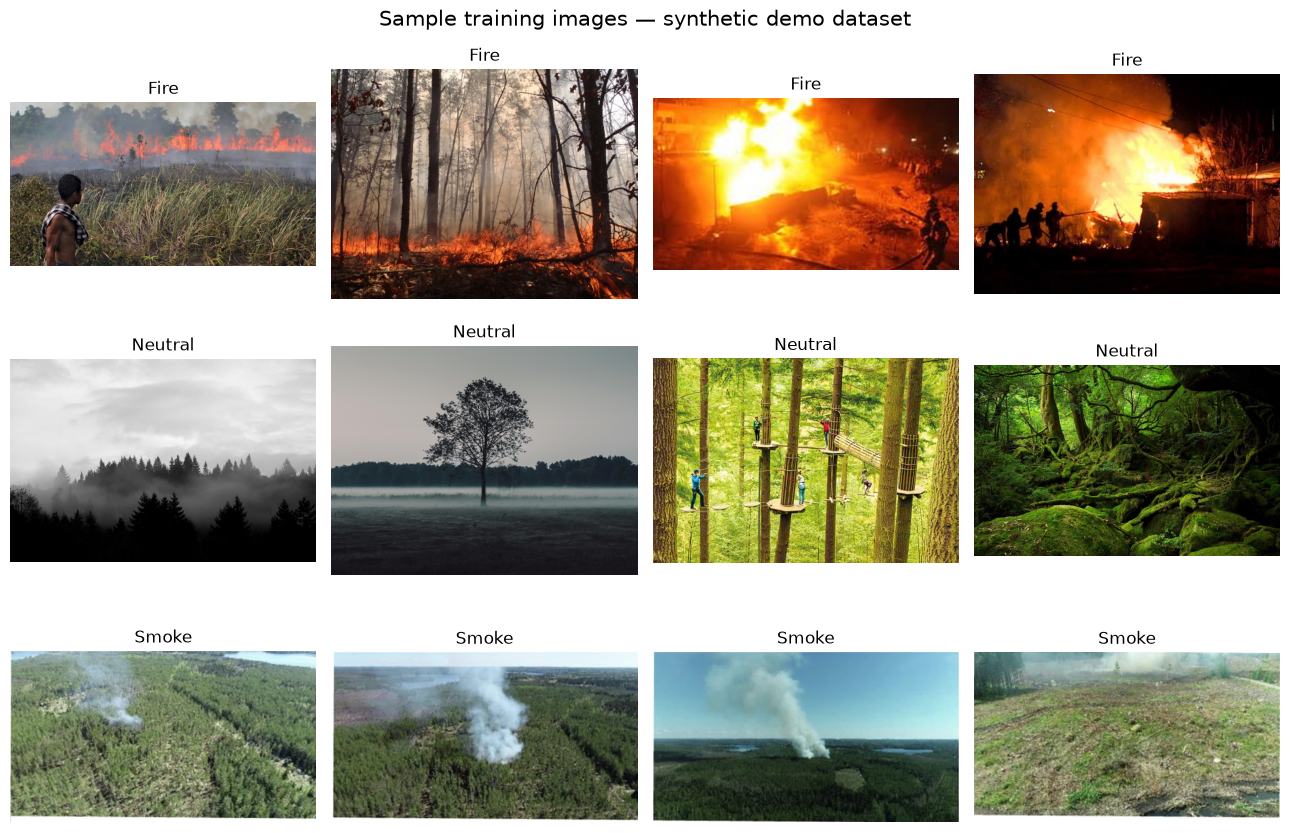

In [5]:
# Hiển thị một số ảnh mẫu ở từng lớp.
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
class_names = train_ds_raw.classes
for row, class_name in enumerate(class_names):
    indices = [i for i, (_, label) in enumerate(train_ds_raw.samples)
               if train_ds_raw.classes[label] == class_name][:4]
    for col, ax in enumerate(axes[row]):
        if col < len(indices):
            image, label = train_ds_raw[indices[col]]
            ax.imshow(image)
            ax.set_title(class_name)
        ax.axis("off")
plt.suptitle("Sample training images — synthetic demo dataset", fontsize=15)
plt.tight_layout()
plt.show()


## 4. Tiền xử lý ảnh và DataLoader

ResNet50 nhận tensor kích thước `3 × 224 × 224`. Pipeline dưới đây resize ảnh, crop về 224×224, chuyển sang tensor và chuẩn hóa từng kênh RGB.

In [6]:
IMAGE_SIZE = 224
BATCH_SIZE = 4
NUM_WORKERS = 0  # 0 ổn định hơn trên Windows/Jupyter

transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),
])

train_dataset = datasets.ImageFolder(str(train_dir), transform=transform)
test_dataset = datasets.ImageFolder(str(test_dir), transform=transform)
assert train_dataset.classes == test_dataset.classes

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=NUM_WORKERS)

xb, yb = next(iter(train_loader))
print("Batch image tensor:", tuple(xb.shape))
print("Batch labels:", yb.tolist())
print("Classes:", train_dataset.classes)


Batch image tensor: (4, 3, 224, 224)
Batch labels: [0, 0, 0, 0]
Classes: ['Fire', 'Neutral', 'Smoke']


## 5. Khởi tạo mô hình ResNet50

Notebook sử dụng `weights=None` để không cần tải pretrained weights từ Internet. Vì vậy model được khởi tạo ngẫu nhiên và cần dữ liệu thực tế đủ lớn để học tốt.

In [7]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = len(train_dataset.classes)

model = models.resnet50(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, NUM_CLASSES)
model = model.to(DEVICE)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(model)
print("Device:", DEVICE)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

## 6. Chạy quá trình Training

Cell này gọi chính file `train.py` trong dự án. Bạn sẽ thấy progress bar theo từng batch; chi tiết loss/accuracy của từng batch được ghi vào `checkpoints/logs/training.log`.

Có thể sửa `EPOCHS` và `BATCH_SIZE` ở đây. Bộ demo mặc định 3 epochs để kiểm tra pipeline.

In [8]:

from pathlib import Path
import sys
import subprocess

# Tìm chính xác thư mục chứa train.py
candidates = [
    Path.cwd().resolve(),
    Path.cwd().resolve().parent,
    DATA_DIR.resolve().parent,
]

ROOT = None

for folder in candidates:
    if (folder / "train.py").is_file():
        ROOT = folder
        break

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy train.py. "
        "Hãy kiểm tra thư mục gốc dự án."
    )

TRAIN_SCRIPT = ROOT / "train.py"
OUTPUT_DIR = ROOT / "checkpoints"

# Kiểm tra Dataset
assert (DATA_DIR / "Train").is_dir(), "Thiếu thư mục Train"
assert (DATA_DIR / "Test").is_dir(), "Thiếu thư mục Test"

print("Project root:", ROOT)
print("Training script:", TRAIN_SCRIPT)
print("Dataset:", DATA_DIR)
print("Python:", sys.executable)

EPOCHS = 3
BATCH_SIZE = 4

cmd = [
    sys.executable,
    str(TRAIN_SCRIPT),
    "--data_dir", str(DATA_DIR.resolve()),
    "--epochs", str(EPOCHS),
    "--batch_size", str(BATCH_SIZE),
    "--workers", "0",
    "--output_dir", str(OUTPUT_DIR.resolve()),
]

print("\nStarting Wildfire Detection Training...")
print("Command:", subprocess.list2cmdline(cmd))

# Hiển thị đầy đủ lỗi nếu Training thất bại
result = subprocess.run(
    cmd,
    cwd=str(ROOT),
    text=True,
    capture_output=True
)

print("\n========== TRAINING OUTPUT ==========")
print(result.stdout)

if result.returncode != 0:
    print("\n========== ERROR DETAILS ==========")
    print(result.stderr)
    raise RuntimeError(
        f"Training failed with exit code {result.returncode}. "
        "Xem ERROR DETAILS ở phía trên."
    )

print("\nTRAINING COMPLETED SUCCESSFULLY!")


Project root: D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python
Training script: D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\train.py
Dataset: D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\Wildfire-smoke
Python: c:\Users\MSI\AppData\Local\Programs\Python\Python311\python.exe

Starting Wildfire Detection Training...
Command: c:\Users\MSI\AppData\Local\Programs\Python\Python311\python.exe D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\train.py --data_dir D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\Wildfire-smoke --epochs 3 --batch_size 4 --workers 0 --output_dir D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\checkpoints


Exception in thread Thread-5 (_readerthread):
Traceback (most recent call last):
  File "c:\Users\MSI\AppData\Local\Programs\Python\Python311\Lib\threading.py", line 1045, in _bootstrap_inner
    self.run()
  File "c:\Users\MSI\AppData\Local\Programs\Python\Python311\Lib\threading.py", line 982, in run
    self._target(*self._args, **self._kwargs)
  File "c:\Users\MSI\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "c:\Users\MSI\AppData\Local\Programs\Python\Python311\Lib\encodings\cp1252.py", line 23, in decode
    return codecs.charmap_decode(input,self.errors,decoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'charmap' codec can't decode byte 0x8f in position 1496: character maps to <undefined>



========== TRAINING OUTPUT ==========


TRAINING COMPLETED SUCCESSFULLY!


## 7. Phân tích Accuracy và Loss theo Epoch

Hai biểu đồ được tạo tự động sau mỗi epoch. Đường train/test giúp quan sát xu hướng học và dấu hiệu overfitting; với dataset demo nhỏ, không nên suy luận hiệu năng thực tế.

,epoch,train_loss,train_accuracy,test_loss,test_accuracy,learning_rate,seconds
0,1,0.644673,0.792741,0.351318,0.890162,0.0001,330.61
1,2,0.436770,0.846227,0.270419,0.910220,0.0001,502.30
2,3,0.417766,0.856734,0.279895,0.903534,0.0001,1758.10


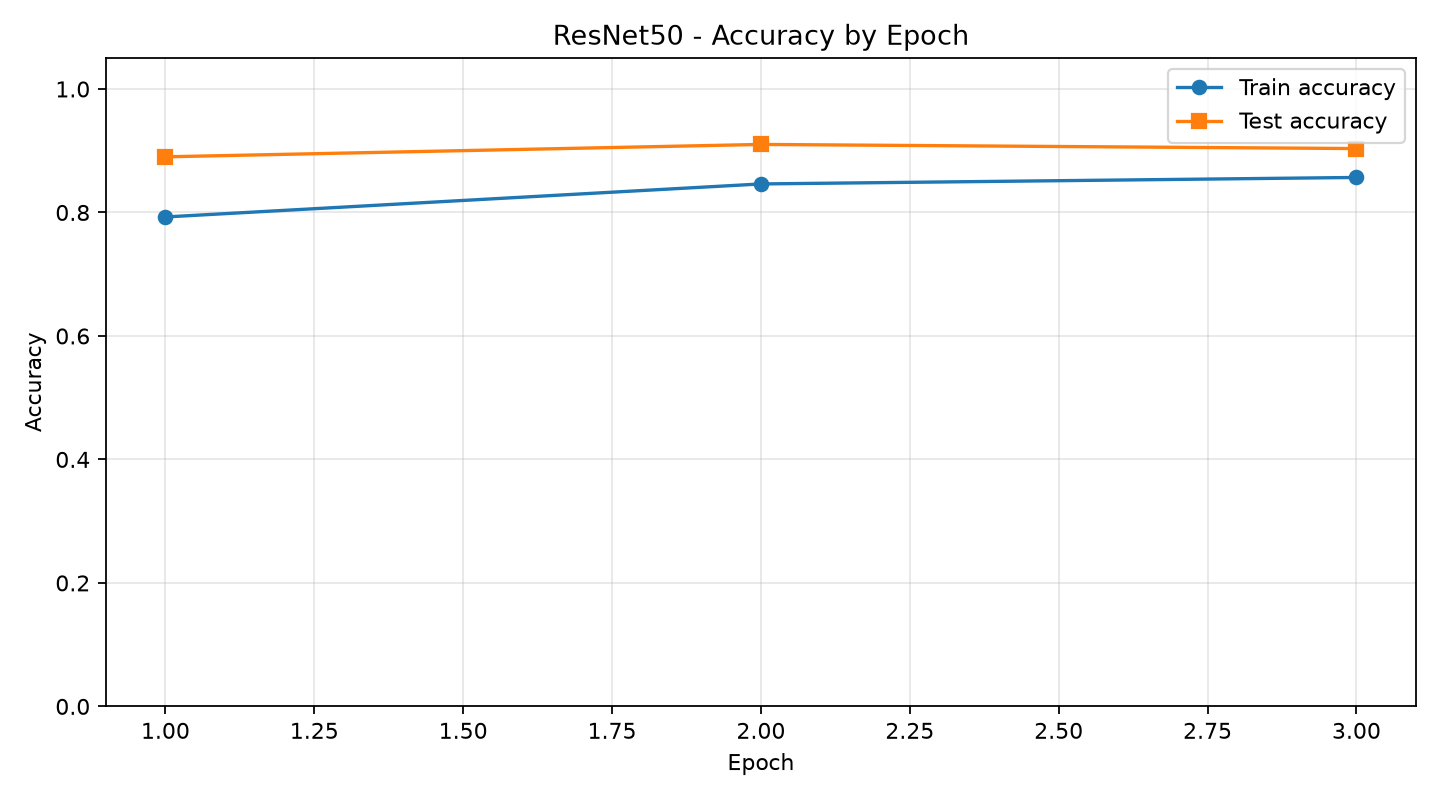

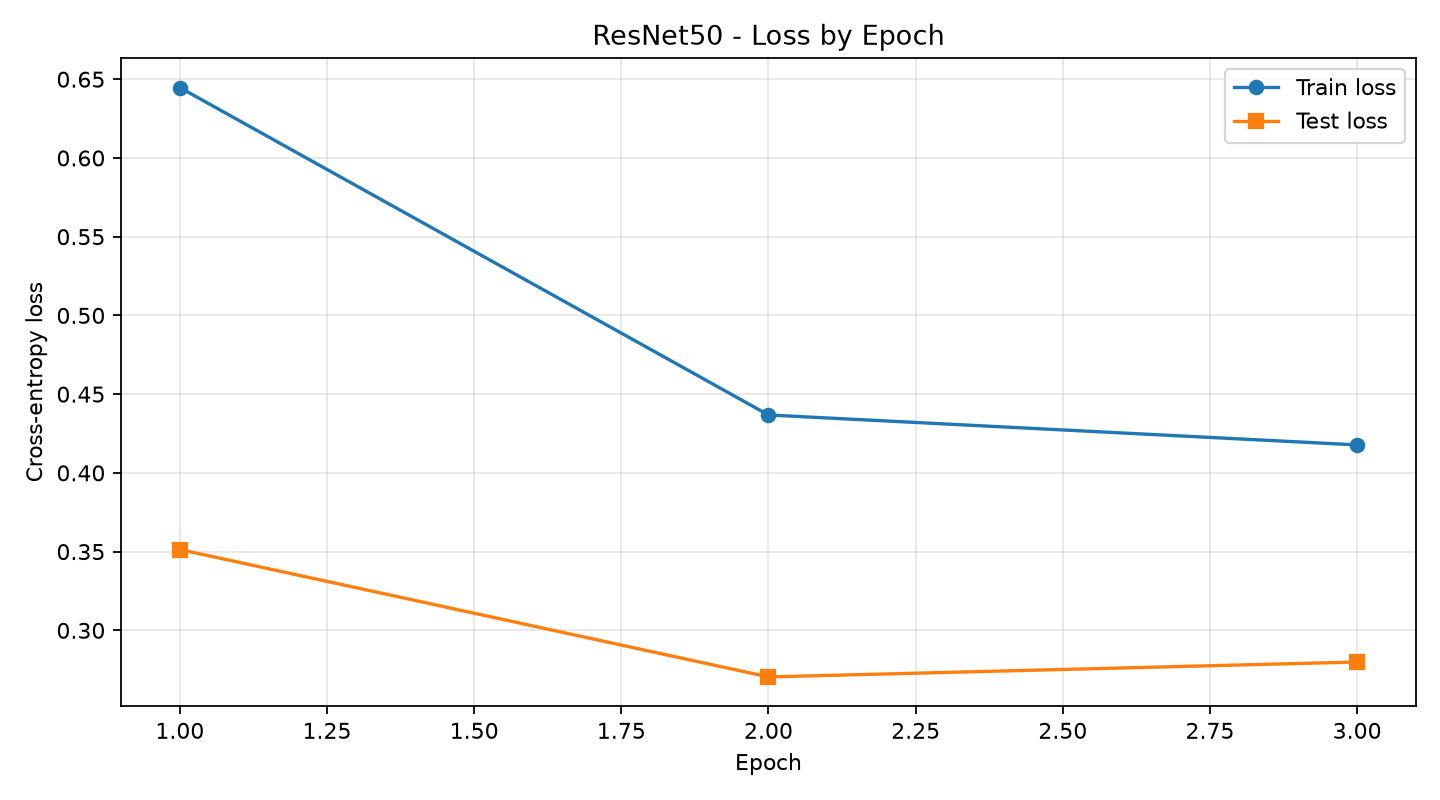

In [9]:
import pandas as pd
history_path = OUTPUT_DIR / "history.csv"
assert history_path.exists(), "Chưa có history.csv. Hãy chạy phần Training trước."
history = pd.read_csv(history_path)
display(history)

acc_path = OUTPUT_DIR / "accuracy_curve.png"
loss_path = OUTPUT_DIR / "loss_curve.png"
for chart_path in [acc_path, loss_path]:
    if chart_path.exists():
        display(Image.open(chart_path))


## 8. Confusion Matrix và Classification Report

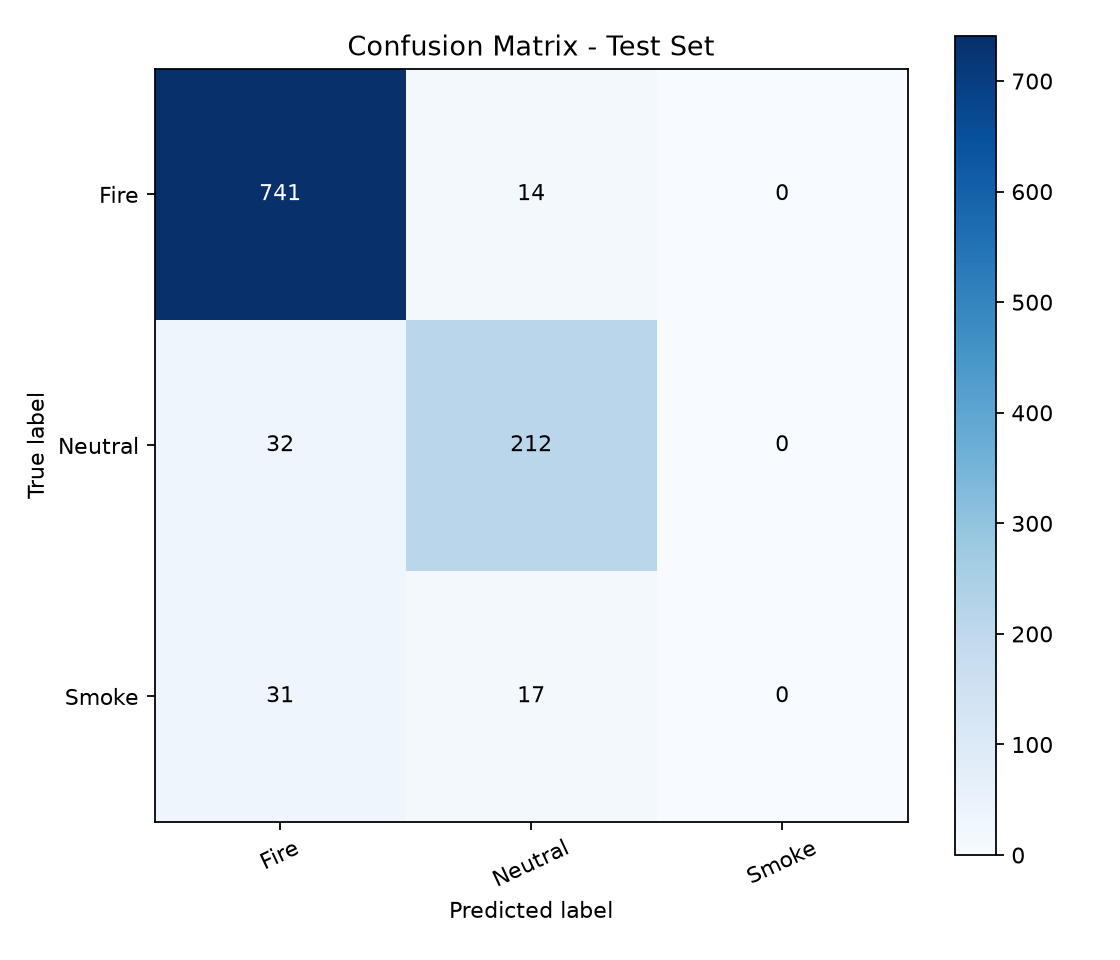

CLASSIFICATION REPORT (Test set)

Class          Precision      Recall    F1-score   Support
Fire              0.9216      0.9815      0.9506       755
Neutral           0.8724      0.8689      0.8706       244
Smoke             0.0000      0.0000      0.0000        48



In [10]:
cm_path = OUTPUT_DIR / "confusion_matrix.png"
report_path = OUTPUT_DIR / "classification_report.txt"

if cm_path.exists():
    display(Image.open(cm_path))
if report_path.exists():
    print(report_path.read_text(encoding="utf-8"))
else:
    print("Chưa có report. Training cần hoàn tất để xuất báo cáo.")


## 9. Kiểm tra checkpoint và dự đoán ảnh

Sau training, checkpoint tốt nhất nằm tại `checkpoints/best_model.pth`. Có thể thay `IMAGE_TO_TEST` bằng đường dẫn ảnh của bạn.

In [11]:
checkpoint = OUTPUT_DIR / "best_model.pth"
print("Checkpoint exists:", checkpoint.exists())
if checkpoint.exists():
    ckpt = torch.load(checkpoint, map_location="cpu", weights_only=True)
    print("Classes:", ckpt["classes"])
    print("Best test accuracy:", ckpt.get("best_test_accuracy"))
    print("Dataset type:", ckpt.get("dataset_type"))

# Chọn một ảnh test mẫu để thử inference.
sample_paths = [p for p in (DATA_DIR / "Test").rglob("*")
                if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}]
if checkpoint.exists() and sample_paths:
    sample_image = sample_paths[0]
    print("Sample image:", sample_image)
    # Dùng script predict.py để kiểm tra cùng pipeline inference của ứng dụng.
    pred_cmd = [sys.executable, "predict.py", "--image", str(sample_image),
                "--checkpoint", str(checkpoint)]
    subprocess.run(pred_cmd, cwd=ROOT, check=True)


Checkpoint exists: True
Classes: ['Fire', 'Neutral', 'Smoke']
Best test accuracy: 0.9102196752626552
Dataset type: synthetic_demo
Sample image: D:\BtapLonComputerVision\Wildfire-Detection-AutoSetup-Notebook-Python\Wildfire-smoke\Test\Fire\fire.1.png


## 10. File kết quả được export

Sau khi training, mở thư mục `checkpoints/`:

| File | Nội dung |
|---|---|
| `best_model.pth` | Trọng số model tốt nhất |
| `history.csv` | Accuracy/Loss từng epoch, mở bằng Excel |
| `accuracy_curve.png` | Biểu đồ train/test accuracy |
| `loss_curve.png` | Biểu đồ train/test loss |
| `confusion_matrix.png` | Ma trận nhầm lẫn |
| `classification_report.txt` | Precision, Recall, F1-score |
| `logs/training.log` | Nhật ký từng mini-batch |

**Ghi nhớ:** Dataset kèm theo là dữ liệu tổng hợp để kiểm tra code. Muốn đánh giá khoa học, cần thay bằng ảnh cháy/khói thực tế có giấy phép, đa dạng bối cảnh, ánh sáng, camera và chia train/test độc lập.